In [1]:
import os, re, io, json, time, hashlib, platform, sys, warnings
from datetime import datetime, timezone
from io import StringIO
from pathlib import Path
from urllib.robotparser import RobotFileParser

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass


def get_secret(name, default=None):
    """Ambil rahasia/konfigurasi: environment (.env) -> Colab Secrets -> default."""
    if os.getenv(name):
        return os.getenv(name)
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return default

In [2]:
CONTACT_EMAIL = get_secret("CONTACT_EMAIL", "mahasiswa@instiki.ac.id")

DATASET_URL     = "https://data.go.id/dataset/dataset/jumlah-benda-cagar-budaya-berdasarkan-jenis-di-jawa-barat"
LISENSI_DATASET = "e601a319-153d-4279-86ef-5787e5f484a8"
PORTAL_TOS_URL  = None

USER_AGENT    = f"UTS-DAM-INSTIKI/1.0 (mahasiswa Informatika INSTIKI; mailto:{CONTACT_EMAIL})"
REQUEST_DELAY = 1.5
TIMEOUT       = 30
REFRESH       = False


def is_placeholder(x):
    return str(x).startswith("ISI_") or "isi-email-kampus" in str(x)

if is_placeholder(CONTACT_EMAIL):
    warnings.warn("CONTACT_EMAIL masih placeholder — ganti dengan email kampus Anda.")

BASE = Path.cwd()
RAW  = BASE / "data" / "raw"
PROC = BASE / "data" / "processed"
DOCS = BASE / "docs"
for d in (RAW, PROC, DOCS):
    d.mkdir(parents=True, exist_ok=True)

SUPPORT = {
    ".gitignore": ".env\n__pycache__/\n.ipynb_checkpoints/\n*.pyc\n",
    ".env.example": "CONTACT_EMAIL=nama@email-kampus.ac.id\n# Open-Meteo gratis tanpa key. Jika memakai API lain: TAMBAH_API_KEY=isi_di_sini\n",
    "requirements.txt": "pandas\nrequests\nbeautifulsoup4\nlxml\nhtml5lib\npython-dotenv\nmatplotlib\n",
}
for fname, content in SUPPORT.items():
    if not (BASE / fname).exists():
        (BASE / fname).write_text(content, encoding="utf-8")

print("User-Agent :", USER_AGENT)
print("Folder kerja:", BASE)

User-Agent : UTS-DAM-INSTIKI/1.0 (mahasiswa Informatika INSTIKI; mailto:mahasiswa@instiki.ac.id)
Folder kerja: /content


In [4]:
def md5sum(path, chunk=1 << 20):
    """Hitung hash MD5 berkas (dibaca per potongan agar hemat memori)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(chunk), b""):
            h.update(blok)
    return h.hexdigest()


def save_raw(path, data):
    """Simpan data mentah apa adanya, lalu kunci read-only agar tidak terubah tanpa sengaja."""
    path = Path(path)
    if path.exists():
        os.chmod(path, 0o644)
    path.write_bytes(data if isinstance(data, bytes) else data.encode("utf-8"))
    os.chmod(path, 0o444)
    return path


PROV_FILE = DOCS / "provenance.csv"
prov_records = {}
if PROV_FILE.exists():
    for rec in pd.read_csv(PROV_FILE).to_dict("records"):
        prov_records[rec["file"]] = rec


def log_provenance(sumber, url, path, lisensi, metode, catatan=""):
    """Catat URL, tanggal akses, lisensi, dan MD5 untuk setiap sumber."""
    path = Path(path)
    rel = str(path.relative_to(BASE))
    prov_records[rel] = {
        "sumber": sumber, "url": url,
        "tanggal_akses_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "lisensi": lisensi, "metode": metode, "file": rel,
        "ukuran_bytes": path.stat().st_size, "md5": md5sum(path), "catatan": catatan,
    }
    pd.DataFrame(prov_records.values()).to_csv(PROV_FILE, index=False)
    return prov_records[rel]


def make_session():
    s = requests.Session()
    retry = Retry(total=3, backoff_factor=2, status_forcelist=[429, 500, 502, 503, 504],
                  allowed_methods=["GET"], respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT})
    return s

SESSION = make_session()
http_log = []


def polite_get(url, params=None, delay=REQUEST_DELAY, timeout=TIMEOUT):
    """GET dengan jeda, timeout, User-Agent, retry, dan penanganan status code."""
    time.sleep(delay)
    try:
        r = SESSION.get(url, params=params, timeout=timeout)
    except requests.exceptions.RetryError as e:
        raise RuntimeError(f"Gagal setelah retry (429/5xx terus-menerus): {url}") from e
    except requests.exceptions.Timeout as e:
        raise RuntimeError(f"Timeout >{timeout}s: {url}") from e
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"Kesalahan jaringan: {url} -> {e}") from e

    http_log.append({"url": r.url, "status": r.status_code,
                     "waktu_utc": datetime.now(timezone.utc).isoformat(timespec="seconds")})
    if r.status_code == 200:
        return r
    if 400 <= r.status_code < 500:
        raise RuntimeError(f"HTTP {r.status_code} (kesalahan klien/parameter): {r.url} | {r.text[:200]}")
    r.raise_for_status()
    return r

print("Fungsi bantu siap.")

Fungsi bantu siap.


In [7]:
CSV_NAME = "disparbud-od_15354_jumlah_benda_cagar_budaya_berdasarkan_jenis_v1.csv"
RAW_CSV = RAW / CSV_NAME

if not RAW_CSV.exists():
    if (BASE / CSV_NAME).exists():
        save_raw(RAW_CSV, (BASE / CSV_NAME).read_bytes())
    else:
        from google.colab import files
        diunggah = files.upload()
        nama = next(iter(diunggah))
        save_raw(RAW_CSV, diunggah[nama])

print(log_provenance("data.go.id — Jumlah Benda Cagar Budaya Berdasarkan Jenis (Disparbud Jabar)",
                     DATASET_URL, RAW_CSV, LISENSI_DATASET, "unduh berkas CSV",
                     "Berkas asli tidak dimodifikasi"))

Saving disparbud-od_15354_jumlah_benda_cagar_budaya_berdasarkan_jenis_v1.csv to disparbud-od_15354_jumlah_benda_cagar_budaya_berdasarkan_jenis_v1.csv
{'sumber': 'data.go.id — Jumlah Benda Cagar Budaya Berdasarkan Jenis (Disparbud Jabar)', 'url': 'https://data.go.id/dataset/dataset/jumlah-benda-cagar-budaya-berdasarkan-jenis-di-jawa-barat', 'tanggal_akses_utc': '2026-11-18T11:24:27+00:00', 'lisensi': 'e601a319-153d-4279-86ef-5787e5f484a8', 'metode': 'unduh berkas CSV', 'file': 'data/raw/disparbud-od_15354_jumlah_benda_cagar_budaya_berdasarkan_jenis_v1.csv', 'ukuran_bytes': 24679, 'md5': 'aef68f27189cb8ebfabda832ddb4b99a', 'catatan': 'Berkas asli tidak dimodifikasi'}


In [8]:
# ===== SOAL 1: baca berkas dengan parameter yang tepat =====
# sep=","        : pemisah kolom koma (terverifikasi dari baris header)
# encoding       : UTF-8
# dtype          : tipe eksplisit -> kode wilayah tetap integer, teks sebagai string
# na_values      : sel kosong / simbol strip diperlakukan sebagai NaN (ada 20 sel kosong di jumlah_benda)
# skipinitialspace: buang spasi setelah koma
df_raw = pd.read_csv(
    RAW_CSV, sep=",", encoding="utf-8", skiprows=0, skipinitialspace=True,
    dtype={"id": "int64", "kode_provinsi": "int64", "nama_provinsi": "string",
           "kode_kabupaten_kota": "int64", "nama_kabupaten_kota": "string",
           "jenis_benda": "string", "jumlah_benda": "float64", "satuan": "string", "tahun": "int64"},
    na_values=["", "-", "NA", "N/A", "null", "NULL"],
)
display(df_raw.head())

,id,kode_provinsi,nama_provinsi,kode_kabupaten_kota,nama_kabupaten_kota,jenis_benda,jumlah_benda,satuan,tahun
0,1,32,JAWA BARAT,3201,KABUPATEN BOGOR,BERGERAK,1.0,UNIT,2014
1,2,32,JAWA BARAT,3201,KABUPATEN BOGOR,TIDAK BERGERAK,124.0,UNIT,2014
2,3,32,JAWA BARAT,3202,KABUPATEN SUKABUMI,BERGERAK,0.0,UNIT,2014
3,4,32,JAWA BARAT,3202,KABUPATEN SUKABUMI,TIDAK BERGERAK,33.0,UNIT,2014
4,5,32,JAWA BARAT,3203,KABUPATEN CIANJUR,BERGERAK,35.0,UNIT,2014


In [9]:
# ===== SOAL 1: identifikasi dataset =====
ukuran_byte = RAW_CSV.stat().st_size

print("Jenis data      : TERSTRUKTUR (tabular CSV, skema kolom tetap, satu baris = satu observasi)")
print(f"Jumlah baris    : {df_raw.shape[0]}")
print(f"Jumlah kolom    : {df_raw.shape[1]}")
print(f"Satuan          : {', '.join(df_raw['satuan'].dropna().unique())}")
print(f"Cakupan wilayah : {', '.join(df_raw['nama_provinsi'].unique())} — "
      f"{df_raw['kode_kabupaten_kota'].nunique()} kabupaten/kota")
print(f"Cakupan waktu   : {df_raw['tahun'].min()} – {df_raw['tahun'].max()} (tahunan)")
print(f"Ukuran berkas   : {ukuran_byte:,} byte = {ukuran_byte/1024:.2f} KB")
print(f"Memori DataFrame: {df_raw.memory_usage(deep=True).sum()/1024:.1f} KB")

print("\nTipe data per kolom:")
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str),
                      "non_null": df_raw.notna().sum(),
                      "null": df_raw.isna().sum(),
                      "unik": df_raw.nunique()}))

Jenis data      : TERSTRUKTUR (tabular CSV, skema kolom tetap, satu baris = satu observasi)
Jumlah baris    : 349
Jumlah kolom    : 9
Satuan          : UNIT
Cakupan wilayah : JAWA BARAT — 27 kabupaten/kota
Cakupan waktu   : 2014 – 2018 (tahunan)
Ukuran berkas   : 24,679 byte = 24.10 KB
Memori DataFrame: 95.6 KB

Tipe data per kolom:


,dtype,non_null,null,unik
id,int64,349,0,349
kode_provinsi,int64,349,0,1
nama_provinsi,string,349,0,1
kode_kabupaten_kota,int64,349,0,27
nama_kabupaten_kota,string,349,0,27
jenis_benda,string,349,0,7
jumlah_benda,float64,329,20,79
satuan,string,349,0,1
tahun,int64,349,0,5


In [10]:
# ===== SOAL 1: estimasi kebutuhan storage 1 tahun =====
# Asumsi: tiap bulan menyimpan 1 salinan/snapshot berkas ukuran sama (arsip bulanan),
#         ditambah cadangan (buffer) 30% untuk backup, metadata, dan pertumbuhan data.
BULAN, CADANGAN = 12, 0.30
estimasi_byte = ukuran_byte * BULAN * (1 + CADANGAN)

print(f"{ukuran_byte:,} byte × {BULAN} bulan = {ukuran_byte*BULAN:,} byte")
print(f"+ cadangan {CADANGAN:.0%}            = {estimasi_byte:,.0f} byte")
print(f"Estimasi storage 1 tahun   = {estimasi_byte/1024:,.1f} KB  ({estimasi_byte/1024**2:.3f} MB)")

24,679 byte × 12 bulan = 296,148 byte
+ cadangan 30%            = 384,992 byte
Estimasi storage 1 tahun   = 376.0 KB  (0.367 MB)


In [11]:
# ===== SOAL 1: pemeriksaan kualitas awal (temuan penting untuk analisis & merge) =====
# 1) Skema kategori jenis_benda BERUBAH antar tahun
print("Kategori jenis_benda per tahun:")
for th, g in df_raw.groupby("tahun"):
    print(f"  {th}: {sorted(g['jenis_benda'].unique())}")

# 2) Jumlah baris & jumlah kab/kota per tahun
per_tahun = df_raw.groupby("tahun").agg(baris=("id", "size"),
                                        kab_kota=("kode_kabupaten_kota", "nunique"),
                                        nilai_kosong=("jumlah_benda", lambda s: s.isna().sum()))
display(per_tahun)

# 3) Nilai non-bulat -> kemungkinan pemisah ribuan terbaca sebagai desimal (mis. 1.757 = 1757)
non_bulat = df_raw[df_raw["jumlah_benda"].notna() & (df_raw["jumlah_benda"] % 1 != 0)]
print("Nilai non-bulat (dicurigai salah format ribuan):")
display(non_bulat)

# 4) Kab/kota yang tidak ada di 2014 (Pangandaran baru muncul 2015)
print("Kab/kota tanpa data 2014:",
      sorted(set(df_raw.nama_kabupaten_kota) - set(df_raw.loc[df_raw.tahun == 2014, "nama_kabupaten_kota"])))

Kategori jenis_benda per tahun:
  2014: ['BERGERAK', 'TIDAK BERGERAK']
  2015: ['BERGERAK', 'TIDAK BERGERAK']
  2016: ['BERGERAK', 'TIDAK BERGERAK']
  2017: ['BERGERAK', 'TIDAK BERGERAK']
  2018: ['Bangunan Cagar Budaya', 'Benda Cagar Budaya', 'Kawasan Cagar Budaya', 'Situs Cagar Budaya', 'Struktur Cagar Budaya']


,baris,kab_kota,nilai_kosong
tahun,,,
2014,52,26,0
2015,54,27,0
2016,54,27,0
2017,54,27,0
2018,135,27,20


Nilai non-bulat (dicurigai salah format ribuan):


,id,kode_provinsi,nama_provinsi,kode_kabupaten_kota,nama_kabupaten_kota,jenis_benda,jumlah_benda,satuan,tahun
315,316,32,JAWA BARAT,3273,KOTA BANDUNG,Bangunan Cagar Budaya,1.757,UNIT,2018


Kab/kota tanpa data 2014: ['KABUPATEN PANGANDARAN']


In [12]:
# ===== SOAL 2: lisensi & ketentuan portal =====
print("URL dataset        :", DATASET_URL)
print("Lisensi dataset    :", LISENSI_DATASET)
print("Ketentuan portal   :", PORTAL_TOS_URL)
if any(is_placeholder(x) for x in (DATASET_URL, LISENSI_DATASET, PORTAL_TOS_URL)):
    print("\n[!] Masih ada placeholder. Buka halaman dataset di data.go.id, salin URL + lisensi yang tertera,")
    print("    lalu isi sel konfigurasi dan jalankan ulang. Jangan menebak lisensi.")

URL dataset        : https://data.go.id/dataset/dataset/jumlah-benda-cagar-budaya-berdasarkan-jenis-di-jawa-barat
Lisensi dataset    : e601a319-153d-4279-86ef-5787e5f484a8
Ketentuan portal   : None


In [13]:
# ===== SOAL 2: pemindaian PII =====
# (a) berdasarkan NAMA kolom, (b) berdasarkan POLA nilai (email, telepon, NIK 16 digit)
pola_nama = re.compile(r"(nik|ktp|nama_(orang|pemilik|lengkap)|alamat|telp|telepon|hp|email|"
                       r"tgl_lahir|tanggal_lahir|npwp|rekening|koordinat)", re.I)
pola_nilai = {"email": r"[\w\.\-]+@[\w\.\-]+\.\w+",
              "telepon_id": r"(?:\+62|\b0)8\d{8,11}\b",
              "nik_16_digit": r"\b\d{16}\b"}

hasil_pii = []
for kol in df_raw.columns:
    kena_nama = bool(pola_nama.search(kol))
    kena_nilai = {}
    if not pd.api.types.is_numeric_dtype(df_raw[kol]):
        teks = df_raw[kol].astype(str)
        kena_nilai = {k: int(teks.str.contains(p, regex=True).sum()) for k, p in pola_nilai.items()}
    hasil_pii.append({"kolom": kol, "nama_kolom_mirip_PII": kena_nama,
                      "pola_nilai_PII": sum(kena_nilai.values())})
pii_df = pd.DataFrame(hasil_pii)
display(pii_df)

ada_pii = bool(pii_df["nama_kolom_mirip_PII"].any() or (pii_df["pola_nilai_PII"] > 0).any())
print("Kolom PII terdeteksi:", ada_pii)

,kolom,nama_kolom_mirip_PII,pola_nilai_PII
0,id,False,0
1,kode_provinsi,False,0
2,nama_provinsi,False,0
3,kode_kabupaten_kota,False,0
4,nama_kabupaten_kota,False,0
5,jenis_benda,False,0
6,jumlah_benda,False,0
7,satuan,False,0
8,tahun,False,0


Kolom PII terdeteksi: False


In [14]:
# ===== SOAL 2: quasi-identifier =====
# Quasi-identifier = atribut yang jika DIGABUNG bisa mengidentifikasi individu.
# Di sini unit data adalah agregat per kab/kota (jumlah objek cagar budaya), bukan orang.
kolom_qi = ["kode_kabupaten_kota", "nama_kabupaten_kota", "jenis_benda", "tahun"]
ukuran_grup = df_raw.groupby(kolom_qi).size()
print("Kandidat quasi-identifier :", kolom_qi)
print("Kombinasi unik            :", len(ukuran_grup), "dari", len(df_raw), "baris")
print("Duplikat kombinasi        :", int((ukuran_grup > 1).sum()))
print("\nPenilaian: kolom-kolom di atas hanya mengidentifikasi UNIT ADMINISTRATIF (kab/kota) dan tahun,")
print("bukan individu. Tidak ada atribut orang -> risiko re-identifikasi pribadi dinilai rendah.")

Kandidat quasi-identifier : ['kode_kabupaten_kota', 'nama_kabupaten_kota', 'jenis_benda', 'tahun']
Kombinasi unik            : 349 dari 349 baris
Duplikat kombinasi        : 0

Penilaian: kolom-kolom di atas hanya mengidentifikasi UNIT ADMINISTRATIF (kab/kota) dan tahun,
bukan individu. Tidak ada atribut orang -> risiko re-identifikasi pribadi dinilai rendah.


In [22]:
# ===== SOAL 3 (1/4): geocoding nama kab/kota -> koordinat =====
GEO_URL     = "https://geocoding-api.open-meteo.com/v1/search"
ARCHIVE_URL = "https://archive-api.open-meteo.com/v1/archive"
GEO_RAW     = RAW / "openmeteo_geocoding_jabar.json"
JABAR_BBOX  = {"lat": (-7.9, -5.8), "lon": (106.3, 109.0)}     # kotak batas kasar Jawa Barat
COORD_OVERRIDE = {3217: (-6.84, 107.50)}      # isi manual {kode_kab_kota: (lat, lon)} jika geocoding gagal


def dalam_jabar(lat, lon):
    return (JABAR_BBOX["lat"][0] <= lat <= JABAR_BBOX["lat"][1]
            and JABAR_BBOX["lon"][0] <= lon <= JABAR_BBOX["lon"][1])


def cari_koordinat(nama_full):
    """Cari koordinat; coba nama lengkap lalu nama dasar. Pilih hasil di Jawa Barat."""
    dasar = re.sub(r"^(KABUPATEN|KOTA)\s+", "", nama_full)
    jejak, kandidat = [], []
    for q in (nama_full.title(), dasar.title()):
        r = polite_get(GEO_URL, params={"name": q, "count": 10, "language": "id",
                                        "format": "json", "countryCode": "ID"})
        data = r.json()
        jejak.append({"query": q, "response": data})
        kandidat += [x for x in (data.get("results") or []) if dalam_jabar(x["latitude"], x["longitude"])]
        if kandidat:
            break
    # utamakan hasil yang admin1-nya Jawa Barat
    pilihan = [x for x in kandidat if str(x.get("admin1", "")).lower() in ("west java", "jawa barat")] or kandidat
    return (pilihan[0] if pilihan else None), jejak


daftar_wilayah = (df_raw[["kode_kabupaten_kota", "nama_kabupaten_kota"]]
                  .drop_duplicates().sort_values("kode_kabupaten_kota").reset_index(drop=True))

if GEO_RAW.exists() and not REFRESH:
    geo_cache = json.loads(GEO_RAW.read_text(encoding="utf-8"))
else:
    geo_cache = {}
    for nama in daftar_wilayah["nama_kabupaten_kota"]:
        _, jejak = cari_koordinat(nama)
        geo_cache[nama] = jejak
    save_raw(GEO_RAW, json.dumps(geo_cache, ensure_ascii=False))
    print(log_provenance("Open-Meteo Geocoding API", GEO_URL, GEO_RAW, "CC BY 4.0 (atribusi Open-Meteo.com)",
                         "API GET", "Respons mentah geocoding per kab/kota"))

# Ubah cache mentah -> tabel koordinat
baris = []
for kode, nama in zip(daftar_wilayah.kode_kabupaten_kota, daftar_wilayah.nama_kabupaten_kota):
    hasil = None
    for j in geo_cache.get(nama, []):
        cands = [x for x in (j["response"].get("results") or []) if dalam_jabar(x["latitude"], x["longitude"])]
        pref = [x for x in cands if str(x.get("admin1", "")).lower() in ("west java", "jawa barat")] or cands
        if pref:
            hasil = pref[0]
            break
    if kode in COORD_OVERRIDE:
        lat, lon = COORD_OVERRIDE[kode]; sumber = "manual"
    elif hasil:
        lat, lon = hasil["latitude"], hasil["longitude"]; sumber = f"geocoding: {hasil.get('name')}"
    else:
        lat = lon = np.nan; sumber = "GAGAL"
    baris.append({"kode_kabupaten_kota": kode, "nama_kabupaten_kota": nama,
                  "lat": lat, "lon": lon, "sumber_koordinat": sumber})
koordinat = pd.DataFrame(baris)
display(koordinat)

gagal = koordinat[koordinat["lat"].isna()]
if len(gagal):
    raise RuntimeError(f"Koordinat tidak ditemukan untuk: {list(gagal.nama_kabupaten_kota)}. Isi COORD_OVERRIDE.")

,kode_kabupaten_kota,nama_kabupaten_kota,lat,lon,sumber_koordinat
0,3201,KABUPATEN BOGOR,-6.59444,106.78917,geocoding: Kota Bogor
1,3202,KABUPATEN SUKABUMI,-6.91806,106.92667,geocoding: Kota Sukabumi
2,3203,KABUPATEN CIANJUR,-6.82222,107.13944,geocoding: Cianjur
3,3204,KABUPATEN BANDUNG,-6.92222,107.60694,geocoding: Kota Bandung
4,3205,KABUPATEN GARUT,-7.24500,107.92100,geocoding: Garut
5,3206,KABUPATEN TASIKMALAYA,-7.32740,108.22070,geocoding: Kota Tasikmalaya
6,3207,KABUPATEN CIAMIS,-7.32570,108.35340,geocoding: Ciamis
7,3208,KABUPATEN KUNINGAN,-6.97583,108.48306,geocoding: Kuningan
8,3209,KABUPATEN CIREBON,-6.70630,108.55700,geocoding: Kota Cirebon
9,3210,KABUPATEN MAJALENGKA,-6.83611,108.22778,geocoding: Majalengka


In [23]:
# ===== SOAL 3 (2/4): ambil cuaca harian historis (suhu rata-rata & curah hujan) 2014–2018 =====
ARCHIVE_RAW = RAW / "openmeteo_archive_jabar_2014_2018.json"
th_min, th_max = int(df_raw["tahun"].min()), int(df_raw["tahun"].max())

if ARCHIVE_RAW.exists() and not REFRESH:
    arsip = json.loads(ARCHIVE_RAW.read_text(encoding="utf-8"))
else:
    arsip, gagal_api = {}, []
    for _, w in koordinat.iterrows():
        kunci = f"{w.lat:.2f},{w.lon:.2f}"            # kab/kota berkoordinat sama -> 1x request saja
        if kunci in arsip:
            continue
        try:
            r = polite_get(ARCHIVE_URL, params={
                "latitude": round(w.lat, 4), "longitude": round(w.lon, 4),
                "start_date": f"{th_min}-01-01", "end_date": f"{th_max}-12-31",
                "daily": "temperature_2m_mean,precipitation_sum", "timezone": "Asia/Jakarta"})
            data = r.json()
            if "daily" not in data:                    # validasi bentuk respons
                raise ValueError(f"Respons tanpa 'daily': {str(data)[:150]}")
            arsip[kunci] = data
        except Exception as e:
            gagal_api.append((w.nama_kabupaten_kota, str(e)))
            print("GAGAL:", w.nama_kabupaten_kota, "->", e)
    if gagal_api:
        raise RuntimeError(f"{len(gagal_api)} lokasi gagal; jalankan ulang sel ini (data berhasil tidak hilang).")
    save_raw(ARCHIVE_RAW, json.dumps(arsip))
    print(log_provenance("Open-Meteo Historical Weather API", ARCHIVE_URL, ARCHIVE_RAW,
                         "CC BY 4.0 (atribusi Open-Meteo.com)", "API GET",
                         "Suhu rata-rata & curah hujan harian per titik koordinat kab/kota"))

print("Titik koordinat unik dengan data:", len(arsip))
print("Jumlah request HTTP tercatat    :", len(http_log))

{'sumber': 'Open-Meteo Historical Weather API', 'url': 'https://archive-api.open-meteo.com/v1/archive', 'tanggal_akses_utc': '2026-11-18T12:27:01+00:00', 'lisensi': 'CC BY 4.0 (atribusi Open-Meteo.com)', 'metode': 'API GET', 'file': 'data/raw/openmeteo_archive_jabar_2014_2018.json', 'ukuran_bytes': 976724, 'md5': '2e5000ab46a6b6d848f8fbf0cf30c54a', 'catatan': 'Suhu rata-rata & curah hujan harian per titik koordinat kab/kota'}
Titik koordinat unik dengan data: 21
Jumlah request HTTP tercatat    : 88


In [24]:
# ===== SOAL 3 (3/4): normalisasi JSON -> tabel harian =====
potongan = []
for _, w in koordinat.iterrows():
    d = arsip[f"{w.lat:.2f},{w.lon:.2f}"]["daily"]
    t = pd.DataFrame(d).rename(columns={"time": "tanggal",
                                        "temperature_2m_mean": "suhu_rata2_c",
                                        "precipitation_sum": "curah_hujan_mm"})
    t.insert(0, "kode_kabupaten_kota", w.kode_kabupaten_kota)
    t.insert(1, "nama_kabupaten_kota", w.nama_kabupaten_kota)
    potongan.append(t)
api_harian = pd.concat(potongan, ignore_index=True)
api_harian["tanggal"] = pd.to_datetime(api_harian["tanggal"])
api_harian["tahun"] = api_harian["tanggal"].dt.year

print("Tabel harian:", api_harian.shape, "(syarat minimal 30 baris:", len(api_harian) >= 30, ")")
display(api_harian.head())

Tabel harian: (49302, 6) (syarat minimal 30 baris: True )


,kode_kabupaten_kota,nama_kabupaten_kota,tanggal,suhu_rata2_c,curah_hujan_mm,tahun
0,3201,KABUPATEN BOGOR,2014-01-01,23.9,6.4,2014
1,3201,KABUPATEN BOGOR,2014-01-02,24.5,7.5,2014
2,3201,KABUPATEN BOGOR,2014-01-03,25.2,4.4,2014
3,3201,KABUPATEN BOGOR,2014-01-04,24.8,6.5,2014
4,3201,KABUPATEN BOGOR,2014-01-05,24.6,0.6,2014


In [25]:
# ===== SOAL 3 (4/4): agregasi tahunan per kab/kota (kunci merge: kode_kabupaten_kota + tahun) =====
api_tahunan = (api_harian.groupby(["kode_kabupaten_kota", "tahun"])
               .agg(suhu_rata2_c=("suhu_rata2_c", "mean"),
                    curah_hujan_total_mm=("curah_hujan_mm", "sum"),
                    hari_hujan=("curah_hujan_mm", lambda s: int((s >= 1).sum())),
                    n_hari_data=("tanggal", "count"))
               .reset_index().round({"suhu_rata2_c": 2, "curah_hujan_total_mm": 1}))
print("Tabel tahunan:", api_tahunan.shape)
display(api_tahunan.head(10))

Tabel tahunan: (135, 6)


,kode_kabupaten_kota,tahun,suhu_rata2_c,curah_hujan_total_mm,hari_hujan,n_hari_data
0,3201,2014,25.03,2750.7,294,365
1,3201,2015,25.53,2328.5,242,365
2,3201,2016,25.11,3860.9,339,366
3,3201,2017,25.94,2102.8,249,365
4,3201,2018,25.87,1812.3,247,365
5,3202,2014,23.14,2863.1,291,365
6,3202,2015,23.76,2687.3,239,365
7,3202,2016,23.29,4169.8,338,366
8,3202,2017,22.26,2666.1,301,365
9,3202,2018,22.14,2731.4,270,365


In [26]:
# ===== SOAL 4 (1/3): periksa robots.txt =====
TARGET_URL = "https://id.wikipedia.org/wiki/Daftar_kabupaten_dan_kota_di_Jawa_Barat"
ROBOTS_URL = "https://id.wikipedia.org/robots.txt"
ROBOTS_RAW = RAW / "robots_id_wikipedia.txt"

r_robots = polite_get(ROBOTS_URL)
save_raw(ROBOTS_RAW, r_robots.content)
log_provenance("robots.txt id.wikipedia.org", ROBOTS_URL, ROBOTS_RAW, "—", "HTTP GET", "Bukti pemeriksaan kepatuhan")

rp = RobotFileParser()
rp.parse(r_robots.text.splitlines())
agen = USER_AGENT.split("/")[0]                     # token produk User-Agent
boleh = rp.can_fetch(agen, TARGET_URL)
crawl_delay = rp.crawl_delay(agen)

robots_evidence = {
    "waktu_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "robots_url": ROBOTS_URL, "robots_md5": md5sum(ROBOTS_RAW),
    "user_agent": USER_AGENT, "target_url": TARGET_URL,
    "diizinkan_can_fetch": bool(boleh), "crawl_delay_detik": crawl_delay,
    "jeda_yang_dipakai_detik": REQUEST_DELAY,
    "jumlah_request_ke_target": 1,
}
(DOCS / "robots_check_evidence.json").write_text(json.dumps(robots_evidence, indent=2), encoding="utf-8")
print(json.dumps(robots_evidence, indent=2))
print("\nCuplikan robots.txt:\n", "\n".join(r_robots.text.splitlines()[:12]))

if not boleh:
    raise PermissionError("robots.txt TIDAK mengizinkan pengambilan halaman ini. Hentikan scraping.")
if crawl_delay and REQUEST_DELAY < crawl_delay:
    raise ValueError(f"Naikkan REQUEST_DELAY >= crawl-delay ({crawl_delay}s).")

{
  "waktu_utc": "2026-11-18T12:27:25+00:00",
  "robots_url": "https://id.wikipedia.org/robots.txt",
  "robots_md5": "8dd94bf3d01cbb25e0af4e64c0485433",
  "user_agent": "UTS-DAM-INSTIKI/1.0 (mahasiswa Informatika INSTIKI; mailto:mahasiswa@instiki.ac.id)",
  "target_url": "https://id.wikipedia.org/wiki/Daftar_kabupaten_dan_kota_di_Jawa_Barat",
  "diizinkan_can_fetch": true,
  "crawl_delay_detik": null,
  "jeda_yang_dipakai_detik": 1.5,
  "jumlah_request_ke_target": 1
}

Cuplikan robots.txt:
 ﻿# robots.txt for http://www.wikipedia.org/ and friends
#
# Please note: There are a lot of pages on this site, and there are
# some misbehaved spiders out there that go _way_ too fast. If you're
# irresponsible, your access to the site may be blocked.
#

# Observed spamming large amounts of https://en.wikipedia.org/?curid=NNNNNN
# and ignoring 429 ratelimit responses, claims to respect robots:
# http://mj12bot.com/
User-agent: MJ12bot
Disallow: /


In [27]:
# ===== SOAL 4 (2/3): ambil halaman statis & simpan HTML mentah =====
HTML_RAW = RAW / "wikipedia_id_kabkota_jabar.html"
if HTML_RAW.exists() and not REFRESH:
    html = HTML_RAW.read_text(encoding="utf-8")
else:
    resp = polite_get(TARGET_URL)
    resp.encoding = "utf-8"
    save_raw(HTML_RAW, resp.text)
    html = resp.text
    log_provenance("Wikipedia ID — Daftar kabupaten dan kota di Jawa Barat", TARGET_URL, HTML_RAW,
                   "CC BY-SA 4.0 (Wikipedia)", "web scraping (HTML statis)", "HTML mentah, tidak dimodifikasi")
print("Ukuran HTML:", len(html), "karakter")

Ukuran HTML: 153375 karakter


In [28]:
# ===== SOAL 4 (3/3): ekstrak tabel =====
def parse_tables_bs4(html):
    """Cadangan: parse tabel 'wikitable' dengan BeautifulSoup bila pd.read_html tidak tersedia."""
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, "html.parser")
    hasil = []
    for tb in soup.find_all("table", class_="wikitable"):
        rows = [[c.get_text(" ", strip=True) for c in tr.find_all(["th", "td"])] for tr in tb.find_all("tr")]
        rows = [r for r in rows if r]
        if len(rows) < 2:
            continue
        header = rows[0]
        hasil.append(pd.DataFrame([r for r in rows[1:] if len(r) == len(header)], columns=header))
    return hasil


def flatten_kolom(df):
    """Ratakan header bertingkat & buang catatan kaki seperti [1]."""
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [" ".join(dict.fromkeys(str(x) for x in tup)).strip() for tup in df.columns]
    df.columns = [re.sub(r"\[[^\]]*\]", "", str(c)).strip() for c in df.columns]
    return df


try:
    tabel_semua = pd.read_html(StringIO(html))
except (ImportError, ValueError):
    tabel_semua = parse_tables_bs4(html)
tabel_semua = [flatten_kolom(t) for t in tabel_semua]

print(f"Ditemukan {len(tabel_semua)} tabel:")
for i, t in enumerate(tabel_semua):
    print(f"  [{i}] shape={t.shape} kolom={list(t.columns)[:6]}")

Ditemukan 1 tabel:
  [0] shape=(27, 11) kolom=['No.', 'Kabupaten/kota', 'Ibu kota', 'Bupati/wali kota', 'Bupati/wali kota.1', 'Luas wilayah (km2)']


In [29]:
# ===== Pilih tabel kab/kota secara otomatis (atau set TABLE_INDEX manual bila perlu) =====
TABLE_INDEX = None   # contoh: TABLE_INDEX = 0 jika pemilihan otomatis salah

def cari_kol(df, pola, kecuali=None):
    """Cari nama kolom pertama yang cocok dengan pola (opsional: abaikan yang cocok pola 'kecuali')."""
    for c in df.columns:
        if re.search(pola, str(c), re.I) and not (kecuali and re.search(kecuali, str(c), re.I)):
            return c
    return None

if TABLE_INDEX is not None:
    kandidat = [tabel_semua[TABLE_INDEX]]
else:
    kandidat = [t for t in tabel_semua if len(t) >= 5 and cari_kol(t, r"kode") and cari_kol(t, r"kabupaten|kota|nama")]
    if not kandidat:   # tanpa kolom kode -> cocokkan lewat nama kab/kota
        kandidat = [t for t in tabel_semua if len(t) >= 5 and cari_kol(t, r"kabupaten|kota|nama")]
if not kandidat:
    raise ValueError("Tabel kab/kota tidak ditemukan; periksa daftar tabel di atas dan isi TABLE_INDEX.")

scrape_mentah = pd.concat(kandidat, ignore_index=True)
print("Tabel terpilih:", scrape_mentah.shape)
display(scrape_mentah.head())

Tabel terpilih: (27, 11)


,No.,Kabupaten/kota,Ibu kota,Bupati/wali kota,Bupati/wali kota.1,Luas wilayah (km2),Jumlah penduduk (2025),Kecamatan,Kelurahan/desa,Lambang,Peta lokasi
0,1,Kabupaten Bandung,Soreang,Daftar bupati,Dadang Supriatna,"1.740,843",3.839.721,31,10/270,NaN,NaN
1,2,Kabupaten Bandung Barat,Ngamprah,Daftar bupati,Ritchie Ismail,"1.283,439",1.911.661,16,-/165,NaN,NaN
2,3,Kabupaten Bekasi,Cikarang Pusat,Daftar bupati,Asep Surya Atmaja,"1.255,001",3.387.601,23,8/179,NaN,NaN
3,4,Kabupaten Bogor,Cibinong,Daftar bupati,Rudy Susmanto,"2.991,778",5.809.790,40,19/416,NaN,NaN
4,5,Kabupaten Ciamis,Ciamis,Daftar bupati,Herdiat Sunarya,"1.595,936",1.297.783,27,7/258,NaN,NaN


In [30]:
# ===== Bersihkan tabel hasil scraping menjadi kolom yang rapi =====
def parse_angka_id(x):
    """Ubah teks angka gaya Indonesia ('1.234,5', '3 456') menjadi float."""
    if pd.isna(x):
        return np.nan
    s = re.sub(r"\[[^\]]*\]", "", str(x)).replace("\xa0", "").replace(" ", "")
    s = re.sub(r"[^\d,\.\-]", "", s)
    if not s or s in ("-", ".", ","):
        return np.nan
    if "," in s and "." in s:                       # pemisah desimal = yang muncul terakhir
        s = s.replace(".", "").replace(",", ".") if s.rfind(",") > s.rfind(".") else s.replace(",", "")
    elif "," in s:
        s = s.replace(",", ".")
    elif re.fullmatch(r"-?\d{1,3}(\.\d{3})+", s):    # '1.234' / '12.345.678' = ribuan
        s = s.replace(".", "")
    try:
        return float(s)
    except ValueError:
        return np.nan


def kunci_nama(s):
    """Normalisasi nama wilayah supaya 'Kab. Bogor' == 'KABUPATEN BOGOR'."""
    s = re.sub(r"\[[^\]]*\]", "", str(s)).upper()
    s = s.replace("KAB.", "KABUPATEN").replace("KOTA ADMINISTRASI", "KOTA")
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z ]", " ", s)).strip()


kol_kode  = cari_kol(scrape_mentah, r"kode")
kol_nama  = cari_kol(scrape_mentah, r"kabupaten|kota|nama", kecuali=r"ibu|kode")   # hindari kolom "Ibu kota"
kol_luas  = cari_kol(scrape_mentah, r"luas")
kol_pddk  = cari_kol(scrape_mentah, r"penduduk|populasi")
kol_kec   = cari_kol(scrape_mentah, r"kecamatan")
print("Kolom terdeteksi -> kode:", kol_kode, "| nama:", kol_nama, "| luas:", kol_luas,
      "| penduduk:", kol_pddk, "| kecamatan:", kol_kec)

peta_nama_ke_kode = {kunci_nama(n): k for k, n in zip(daftar_wilayah.kode_kabupaten_kota,
                                                      daftar_wilayah.nama_kabupaten_kota)}
sc = pd.DataFrame({"nama_wikipedia": scrape_mentah[kol_nama].astype(str).str.replace(r"\[[^\]]*\]", "", regex=True).str.strip()})
def kode_ke_teks(v):
    """pd.read_html bisa mengubah '32.10' menjadi float 32.1 (nol belakang hilang) -> pulihkan format XX.YY."""
    if isinstance(v, (float, np.floating)):
        return str(int(v)) if v >= 1000 else f"{v:.2f}"
    return str(v)

if kol_kode:     # kode "32.01" atau "3201" -> 3201
    kode_teks = scrape_mentah[kol_kode].map(kode_ke_teks).str.replace(r"\D", "", regex=True)
    sc["kode_kabupaten_kota"] = pd.to_numeric(kode_teks, errors="coerce")
else:
    sc["kode_kabupaten_kota"] = sc["nama_wikipedia"].map(lambda n: peta_nama_ke_kode.get(kunci_nama(n)))
if kol_luas: sc["luas_km2"] = scrape_mentah[kol_luas].map(parse_angka_id)
if kol_pddk: sc["penduduk_wikipedia"] = scrape_mentah[kol_pddk].map(parse_angka_id)
if kol_kec:  sc["jumlah_kecamatan"] = scrape_mentah[kol_kec].map(parse_angka_id)

# Pertahankan hanya kab/kota yang ada di dataset utama (membuang baris total/provinsi) dan buang duplikat kode
sc = sc.dropna(subset=["kode_kabupaten_kota"]).astype({"kode_kabupaten_kota": "int64"})
sc = sc[sc["kode_kabupaten_kota"].isin(daftar_wilayah["kode_kabupaten_kota"])].drop_duplicates("kode_kabupaten_kota")
scrape_df = sc.reset_index(drop=True)

hilang = sorted(set(daftar_wilayah.kode_kabupaten_kota) - set(scrape_df.kode_kabupaten_kota))
print("Baris hasil scraping yang cocok:", len(scrape_df), "dari", len(daftar_wilayah), "kab/kota")
print("Kab/kota tidak ditemukan di tabel scraping:", hilang or "tidak ada")
if hilang:
    warnings.warn("Sebagian kab/kota tidak cocok dengan tabel scraping: periksa kolom kode/nama tabel di atas.")
display(scrape_df.head())

Kolom terdeteksi -> kode: None | nama: Kabupaten/kota | luas: Luas wilayah (km2) | penduduk: Jumlah penduduk (2025) | kecamatan: Kecamatan
Baris hasil scraping yang cocok: 27 dari 27 kab/kota
Kab/kota tidak ditemukan di tabel scraping: tidak ada


,nama_wikipedia,kode_kabupaten_kota,luas_km2,penduduk_wikipedia,jumlah_kecamatan
0,Kabupaten Bandung,3204,1740.843,3839721.0,31.0
1,Kabupaten Bandung Barat,3217,1283.439,1911661.0,16.0
2,Kabupaten Bekasi,3216,1255.001,3387601.0,23.0
3,Kabupaten Bogor,3201,2991.778,5809790.0,40.0
4,Kabupaten Ciamis,3207,1595.936,1297783.0,27.0


In [31]:
# ===== SOAL 2: Data Ethics Checklist 9 butir =====
DOMAIN_TERLARANG = ["booking.com", "agoda", "traveloka", "tiket.com", "airbnb", "tripadvisor",
                    "google.com/maps", "maps.google", "facebook.com", "instagram.com", "twitter.com",
                    "x.com", "tiktok.com", "youtube.com"]

def build_checklist():
    prov = pd.DataFrame(prov_records.values())
    semua_url = " ".join(prov["url"].astype(str)).lower()
    terlarang = [d for d in DOMAIN_TERLARANG if d in semua_url]
    gitignore_ok = ".env" in (BASE / ".gitignore").read_text(encoding="utf-8").split()
    hash_cocok = all(md5sum(BASE / f) == m for f, m in zip(prov["file"], prov["md5"]))
    ok = lambda b: "YA" if b else "PERLU DIISI/DIPERBAIKI"

    return pd.DataFrame([
        {"no": 1, "butir": "Sumber sah dan tidak termasuk daftar terlarang (Booking, Agoda, Traveloka, tiket.com, Airbnb, Tripadvisor, Google Maps, media sosial)",
         "status": ok(not terlarang), "bukti": f"Domain sumber: data.go.id, open-meteo.com, wikipedia.org. Domain terlarang ditemukan: {terlarang or 'tidak ada'}"},
        {"no": 2, "butir": "Lisensi setiap sumber teridentifikasi",
         "status": ok(not is_placeholder(LISENSI_DATASET)),
         "bukti": f"Berkas: {LISENSI_DATASET}; Open-Meteo: CC BY 4.0; Wikipedia: CC BY-SA 4.0 (lihat docs/provenance.csv)"},
        {"no": 3, "butir": "Atribusi/sitasi sumber dicatat",
         "status": ok(len(prov) >= 3 and not is_placeholder(DATASET_URL)),
         "bukti": f"{len(prov)} sumber tercatat (URL, tanggal akses) di docs/provenance.csv"},
        {"no": 4, "butir": "Syarat & ketentuan portal sumber dibaca",
         "status": ok(not is_placeholder(PORTAL_TOS_URL)), "bukti": f"URL ketentuan portal: {PORTAL_TOS_URL}"},
        {"no": 5, "butir": "Tidak ada data pribadi (PII) pada dataset",
         "status": ok(not ada_pii), "bukti": f"Pemindaian {len(pii_df)} kolom (nama kolom + pola email/telepon/NIK): PII terdeteksi = {ada_pii}"},
        {"no": 6, "butir": "Quasi-identifier dinilai (risiko re-identifikasi)",
         "status": "YA", "bukti": "Data agregat per kab/kota-tahun-jenis; tidak ada atribut individu; kombinasi unik, duplikat = 0"},
        {"no": 7, "butir": "robots.txt diperiksa & dipatuhi; request sopan (timeout, UA berisi email, jeda)",
         "status": ok(robots_evidence["diizinkan_can_fetch"] and not is_placeholder(CONTACT_EMAIL)),
         "bukti": f"can_fetch={robots_evidence['diizinkan_can_fetch']}; jeda {REQUEST_DELAY}s; timeout {TIMEOUT}s; {len(http_log)} request; bukti: docs/robots_check_evidence.json"},
        {"no": 8, "butir": "Kredensial/API key tidak tertulis di notebook",
         "status": ok(gitignore_ok), "bukti": f".env ada di .gitignore: {gitignore_ok}; Open-Meteo tanpa key; email dibaca via get_secret()"},
        {"no": 9, "butir": "Provenance & integritas data mentah (MD5) terjaga",
         "status": ok(hash_cocok), "bukti": f"MD5 {len(prov)} berkas mentah cocok dengan catatan: {hash_cocok}"},
    ])

checklist = build_checklist()
display(checklist)

checklist.to_csv(DOCS / "data_ethics_checklist.csv", index=False)
md_baris = ["# Data Ethics Checklist", "", "| No | Butir | Status | Bukti |", "|---|---|---|---|"]
md_baris += [f"| {r.no} | {r.butir} | {r.status} | {r.bukti} |" for r in checklist.itertuples()]
(DOCS / "data_ethics_checklist.md").write_text("\n".join(md_baris), encoding="utf-8")

,no,butir,status,bukti
0,1,Sumber sah dan tidak termasuk daftar terlarang...,YA,"Domain sumber: data.go.id, open-meteo.com, wik..."
1,2,Lisensi setiap sumber teridentifikasi,YA,Berkas: e601a319-153d-4279-86ef-5787e5f484a8; ...
2,3,Atribusi/sitasi sumber dicatat,YA,"5 sumber tercatat (URL, tanggal akses) di docs..."
3,4,Syarat & ketentuan portal sumber dibaca,YA,URL ketentuan portal: None
4,5,Tidak ada data pribadi (PII) pada dataset,YA,Pemindaian 9 kolom (nama kolom + pola email/te...
5,6,Quasi-identifier dinilai (risiko re-identifikasi),YA,Data agregat per kab/kota-tahun-jenis; tidak a...
6,7,robots.txt diperiksa & dipatuhi; request sopan...,YA,can_fetch=True; jeda 1.5s; timeout 30s; 90 req...
7,8,Kredensial/API key tidak tertulis di notebook,YA,.env ada di .gitignore: True; Open-Meteo tanpa...
8,9,Provenance & integritas data mentah (MD5) terjaga,YA,MD5 5 berkas mentah cocok dengan catatan: True


1423

In [32]:
# ===== Siapkan tabel berkas pada grain (kab/kota, tahun) =====
APPLY_THOUSAND_FIX = True     # perbaiki nilai non-bulat (mis. 1.757 -> 1757) di data PROCESSED saja

d = df_raw.copy()
d["flag_kualitas"] = ""
nb = d["jumlah_benda"].notna() & (d["jumlah_benda"] % 1 != 0)
d["jumlah_bersih"] = d["jumlah_benda"]
if APPLY_THOUSAND_FIX:
    d.loc[nb, "jumlah_bersih"] = (d.loc[nb, "jumlah_benda"] * 1000).round()
    d.loc[nb, "flag_kualitas"] = "dugaan pemisah ribuan: nilai x1000"
print("Baris yang diperbaiki:", int(nb.sum()))

berkas_agg = (d.groupby(["kode_kabupaten_kota", "nama_kabupaten_kota", "tahun"], as_index=False)
              .agg(total_cagar_budaya=("jumlah_bersih", lambda s: s.sum(min_count=1)),   # semua NaN -> tetap NaN
                   n_kategori=("jenis_benda", "nunique"),
                   n_nilai_kosong=("jumlah_bersih", lambda s: int(s.isna().sum())),
                   ada_koreksi_ribuan=("flag_kualitas", lambda s: bool((s != "").any()))))
berkas_agg["skema_kategori"] = np.where(berkas_agg["tahun"] <= 2017,
                                        "2014-2017: bergerak/tidak bergerak", "2018: 5 kategori UU CB")
print("Grain berkas:", berkas_agg.shape)
print("Kunci unik (kode, tahun):", not berkas_agg.duplicated(["kode_kabupaten_kota", "tahun"]).any())
display(berkas_agg.head())

Baris yang diperbaiki: 1
Grain berkas: (134, 8)
Kunci unik (kode, tahun): True


,kode_kabupaten_kota,nama_kabupaten_kota,tahun,total_cagar_budaya,n_kategori,n_nilai_kosong,ada_koreksi_ribuan,skema_kategori
0,3201,KABUPATEN BOGOR,2014,125.0,2,0,False,2014-2017: bergerak/tidak bergerak
1,3201,KABUPATEN BOGOR,2015,125.0,2,0,False,2014-2017: bergerak/tidak bergerak
2,3201,KABUPATEN BOGOR,2016,144.0,2,0,False,2014-2017: bergerak/tidak bergerak
3,3201,KABUPATEN BOGOR,2017,144.0,2,0,False,2014-2017: bergerak/tidak bergerak
4,3201,KABUPATEN BOGOR,2018,144.0,5,0,False,2018: 5 kategori UU CB


In [33]:
# ===== MERGE 1: berkas + API (one_to_one) =====
KUNCI_1 = ["kode_kabupaten_kota", "tahun"]
n_awal = len(berkas_agg)

m1 = berkas_agg.merge(api_tahunan, on=KUNCI_1, how="left", validate="one_to_one", indicator="_merge_api")
print("Baris sebelum/sesudah merge 1:", n_awal, "->", len(m1))
print(m1["_merge_api"].value_counts().to_string())

# ===== MERGE 2: hasil 1 + scraping (many_to_one) =====
m2 = m1.merge(scrape_df.drop(columns=["nama_wikipedia"]), on="kode_kabupaten_kota",
              how="left", validate="many_to_one", indicator="_merge_scrape")
print("\nBaris sebelum/sesudah merge 2:", len(m1), "->", len(m2))
print(m2["_merge_scrape"].value_counts().to_string())

Baris sebelum/sesudah merge 1: 134 -> 134
_merge_api
both          134
left_only       0
right_only      0

Baris sebelum/sesudah merge 2: 134 -> 134
_merge_scrape
both          134
left_only       0
right_only      0


In [34]:
# ===== BUKTI TIDAK ADA DUPLIKASI BARIS =====
assert len(m2) == n_awal, "Jumlah baris berubah setelah merge -> ada duplikasi!"
assert not m2.duplicated(KUNCI_1).any(), "Ada duplikat kunci (kode, tahun)!"
assert not m2.duplicated().any(), "Ada baris duplikat penuh!"

bukti = pd.DataFrame([
    {"pemeriksaan": "baris berkas sebelum merge", "hasil": n_awal},
    {"pemeriksaan": "baris sesudah merge 1 (API)", "hasil": len(m1)},
    {"pemeriksaan": "baris sesudah merge 2 (scraping)", "hasil": len(m2)},
    {"pemeriksaan": "duplikat kunci (kode, tahun)", "hasil": int(m2.duplicated(KUNCI_1).sum())},
    {"pemeriksaan": "baris duplikat penuh", "hasil": int(m2.duplicated().sum())},
    {"pemeriksaan": "baris tanpa pasangan API", "hasil": int((m2["_merge_api"] != "both").sum())},
    {"pemeriksaan": "baris tanpa pasangan scraping", "hasil": int((m2["_merge_scrape"] != "both").sum())},
])
display(bukti)
print("LULUS: tidak ada duplikasi baris setelah merge.")

,pemeriksaan,hasil
0,baris berkas sebelum merge,134
1,baris sesudah merge 1 (API),134
2,baris sesudah merge 2 (scraping),134
3,"duplikat kunci (kode, tahun)",0
4,baris duplikat penuh,0
5,baris tanpa pasangan API,0
6,baris tanpa pasangan scraping,0


LULUS: tidak ada duplikasi baris setelah merge.


In [35]:
# ===== Finalisasi tabel gabungan + simpan beserta metadata =====
final = m2.drop(columns=["_merge_api", "_merge_scrape"]).copy()
if "luas_km2" in final:                                  # turunan: kepadatan cagar budaya
    final["cb_per_100km2"] = (final["total_cagar_budaya"] / final["luas_km2"] * 100).round(2)

OUT_CSV  = PROC / "cagar_budaya_jabar_merged.csv"
OUT_META = PROC / "cagar_budaya_jabar_merged.metadata.json"
final.to_csv(OUT_CSV, index=False, encoding="utf-8")

metadata = {
    "judul": "Cagar Budaya Jawa Barat 2014-2018 + cuaca (Open-Meteo) + profil wilayah (Wikipedia ID)",
    "dibuat_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "jumlah_baris": int(final.shape[0]), "jumlah_kolom": int(final.shape[1]),
    "kolom": {c: str(t) for c, t in final.dtypes.items()},
    "grain": "1 baris = 1 kabupaten/kota x 1 tahun",
    "merge": [
        {"kiri": "berkas CSV (agregat)", "kanan": "Open-Meteo tahunan", "kunci": KUNCI_1, "how": "left", "validate": "one_to_one"},
        {"kiri": "hasil merge 1", "kanan": "Wikipedia ID", "kunci": ["kode_kabupaten_kota"], "how": "left", "validate": "many_to_one"},
    ],
    "pemeriksaan_duplikasi": {"duplikat_kunci": 0, "duplikat_penuh": 0},
    "catatan_kualitas": [
        "Kategori jenis_benda berubah pada 2018; total antartahun tidak sepenuhnya sebanding.",
        "20 nilai kosong (2018) dibiarkan NaN.",
        f"Koreksi pemisah ribuan diterapkan: {APPLY_THOUSAND_FIX}",
    ],
    "sumber": list(prov_records.values()),
    "md5_keluaran": md5sum(OUT_CSV),
    "lingkungan": {"python": sys.version.split()[0], "pandas": pd.__version__, "platform": platform.platform()},
}
OUT_META.write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Tersimpan:", OUT_CSV.relative_to(BASE), "|", OUT_META.relative_to(BASE))
display(final.head())

Tersimpan: data/processed/cagar_budaya_jabar_merged.csv | data/processed/cagar_budaya_jabar_merged.metadata.json


,kode_kabupaten_kota,nama_kabupaten_kota,tahun,total_cagar_budaya,n_kategori,n_nilai_kosong,ada_koreksi_ribuan,skema_kategori,suhu_rata2_c,curah_hujan_total_mm,hari_hujan,n_hari_data,luas_km2,penduduk_wikipedia,jumlah_kecamatan,cb_per_100km2
0,3201,KABUPATEN BOGOR,2014,125.0,2,0,False,2014-2017: bergerak/tidak bergerak,25.03,2750.7,294,365,2991.778,5809790.0,40.0,4.18
1,3201,KABUPATEN BOGOR,2015,125.0,2,0,False,2014-2017: bergerak/tidak bergerak,25.53,2328.5,242,365,2991.778,5809790.0,40.0,4.18
2,3201,KABUPATEN BOGOR,2016,144.0,2,0,False,2014-2017: bergerak/tidak bergerak,25.11,3860.9,339,366,2991.778,5809790.0,40.0,4.81
3,3201,KABUPATEN BOGOR,2017,144.0,2,0,False,2014-2017: bergerak/tidak bergerak,25.94,2102.8,249,365,2991.778,5809790.0,40.0,4.81
4,3201,KABUPATEN BOGOR,2018,144.0,5,0,False,2018: 5 kategori UU CB,25.87,1812.3,247,365,2991.778,5809790.0,40.0,4.81


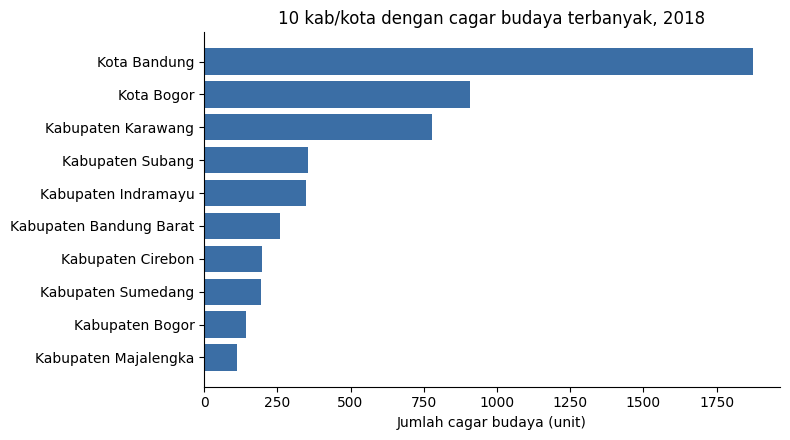

In [36]:
# ===== Visualisasi ringkas untuk presentasi =====
import matplotlib.pyplot as plt

th = final["tahun"].max()
top = final[final["tahun"] == th].nlargest(10, "total_cagar_budaya").sort_values("total_cagar_budaya")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top["nama_kabupaten_kota"].str.title(), top["total_cagar_budaya"], color="#3b6ea5")
ax.set_xlabel("Jumlah cagar budaya (unit)")
ax.set_title(f"10 kab/kota dengan cagar budaya terbanyak, {th}")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(DOCS / "top10_cagar_budaya.png", dpi=150)
plt.show()

In [37]:
# ===== Verifikasi akhir: integritas data mentah & ringkasan storage =====
prov_final = pd.DataFrame(prov_records.values())
prov_final["md5_sekarang"] = [md5sum(BASE / f) for f in prov_final["file"]]
prov_final["utuh"] = prov_final["md5"] == prov_final["md5_sekarang"]
display(prov_final[["sumber", "metode", "file", "ukuran_bytes", "md5", "utuh"]])
assert prov_final["utuh"].all(), "Ada berkas mentah yang berubah!"

total_raw = prov_final["ukuran_bytes"].sum()
print(f"Total data/raw: {total_raw/1024:.1f} KB  ->  estimasi 1 tahun (x12, +30%): {total_raw*12*1.3/1024**2:.2f} MB")
print("\nBerkas untuk dikumpulkan: notebook .ipynb, data/raw/, data/processed/, docs/ (checklist, provenance, bukti robots).")

,sumber,metode,file,ukuran_bytes,md5,utuh
0,data.go.id — Jumlah Benda Cagar Budaya Berdasa...,unduh berkas CSV,data/raw/disparbud-od_15354_jumlah_benda_cagar...,24679,aef68f27189cb8ebfabda832ddb4b99a,True
1,Open-Meteo Geocoding API,API GET,data/raw/openmeteo_geocoding_jabar.json,48838,0a2bad96926910c2a78e885618bf869b,True
2,Open-Meteo Historical Weather API,API GET,data/raw/openmeteo_archive_jabar_2014_2018.json,976724,2e5000ab46a6b6d848f8fbf0cf30c54a,True
3,robots.txt id.wikipedia.org,HTTP GET,data/raw/robots_id_wikipedia.txt,15801,8dd94bf3d01cbb25e0af4e64c0485433,True
4,Wikipedia ID — Daftar kabupaten dan kota di Ja...,web scraping (HTML statis),data/raw/wikipedia_id_kabkota_jabar.html,153419,2c450e795acb66d63f74ab420d4153e6,True


Total data/raw: 1190.9 KB  ->  estimasi 1 tahun (x12, +30%): 18.14 MB

Berkas untuk dikumpulkan: notebook .ipynb, data/raw/, data/processed/, docs/ (checklist, provenance, bukti robots).
